# Классификация ботов

## Описание задачи и обзор решения

**Задача:** по логам пользовательских событий (`data\events.csv.gz`) внутри 24-часового окна наблюдения (`[window_start_ts, window_end_ts)`) определить, является ли сессия (`cookie_id`) автоматизированным ботом (`target = 1`) или реальным пользователем (`target = 0`).

**Целевая метрика:** `Precision @ Recall >= 0.70` (максимальная точность при полноте не менее 70% - реализована в `metric.py`). Выборка характеризуется выраженным дисбалансом классов (~8.1% ботов в обучающей выборке).

**Этапы решения:**
1. **Первичная обработка и проверка целостности данных:** приведение строковых признаков к единому регистру, проверка на пропуски, дубликаты и пересечение `cookie_id` между `train` и `test`.
2. **Разведочный анализ данных (EDA):**
   - анализ временны́х границ сессий и распределения таргета во времени;
   - изучение категориальных признаков лога событий и структуры пропусков (`NaN`);
   - фильтрация событий строго по окну наблюдения `[window_start_ts, window_end_ts)` и проверка согласованности категорий между `train` и `test`.
3. **Генерация признаков (Feature Engineering):**
   - выявление явных сигнатур скриптов и парсеров в `user_agent`, а также конфликтов между заявленной платформой (`platform`) и строкой `user_agent`;
   - расчёт поведенческих агрегатов (число событий, уникальных карточек, глубина и стартовая страница поиска, частота кликов в одни и те же координаты экрана, конверсии в просмотр контактов и отправку сообщений);
   - расчёт временны́х характеристик сессии (минимум, среднее, медиана, СКО и мода интервалов `time_diff` между соседними действиями).
4. **Валидация и моделирование:**
   - разбиение по времени (`Out-of-Time split`), так как тестовая выборка следует строго после обучающей;
   - сравнение с бейзлайном (`RandomForest` на базовых счётчиках) и подбор гиперпараметров градиентного бустинга `CatBoostClassifier` с помощью `Optuna` напрямую под целевую метрику `P@R0.7`.
5. **Формирование финального предсказания:** дообучение лучшей конфигурации модели на всей обучающей выборке и сохранение `submission.csv`.

# Подготовка данных

## Загрузка датафреймов

In [1]:
import os
import random

import numpy as np
import pandas as pd

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

train = pd.read_csv(
    'data/train.csv',
    parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'],
)
test = pd.read_csv(
    'data/test.csv',
    parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'],
)
events = pd.read_csv('data/events.csv.gz', parse_dates=['event_ts'])

print(train.shape, test.shape, events.shape)
print('доля ботов в train:', train.target.mean().round(4))
train.head()


(11091, 5) (4909, 4) (328905, 14)
доля ботов в train: 0.0811


,cookie_id,cookie_created_at,window_start_ts,window_end_ts,target
0,ck_54a059eb7d3ea68b,2025-11-21 09:30:41,2026-04-06,2026-04-07,0
1,ck_7e4de46eeab82974,2025-09-23 10:10:24,2026-04-06,2026-04-07,0
2,ck_9320229ef6304522,2026-03-04 00:08:02,2026-04-06,2026-04-07,0
3,ck_30ccd25bc1714ed9,2026-04-05 10:52:40,2026-04-06,2026-04-07,0
4,ck_a77c5f05948cdeef,2026-01-01 03:54:35,2026-04-06,2026-04-07,0


In [2]:
events.head()


,cookie_id,event_ts,eid,event_name,platform,user_agent,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y
0,ck_5efbea1befdefe1b,2026-04-26 09:11:24,200,item_view,desktop,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,1027450.0,elektronika,kaliningrad,pro,NaN,NaN,NaN,NaN
1,ck_c4ca1434f3778f1d,2026-04-20 14:04:31,100,search_results_view,web,Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:1...,NaN,telefony,habarovsk,NaN,iphone 13 128,4.0,NaN,NaN
2,ck_d274382b19488771,2026-04-13 12:02:56,200,item_view,WEB,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1048743.0,kvartiry_prodazha,kirov,private,NaN,NaN,675.0,276.0
3,ck_fbbed2ff14944ce9,2026-04-08 06:12:14,100,search_results_view,web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,bytovaya_tehnika,novosibirsk,NaN,пылесос dyson,2.0,NaN,NaN
4,ck_56cc15c7c634cb9f,2026-04-12 17:16:05,100,search_results_view,WEB,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,odezhda,sankt-peterburg,NaN,костюм мужской,2.0,NaN,NaN


**Краткая сводка по исходным таблицам:**
* `train` содержит **11 091** уникальную сессию (`cookie_id`), доля целевого класса (`target = 1`) составляет **8.11%** (выраженный дисбаланс классов).
* `test` содержит **4 909** сессий, для которых необходимо предсказать вероятность бота.
* `events` включает **328 905** сырых событий с 14 атрибутами (временные метки, тип события, клиентские метаданные, характеристики карточки, параметры поиска и координаты кликов). В ряде столбцов присутствуют пропуски, природа которых будет исследована далее.

## Первичная предобработка датафреймов

Осуществим первичню (безусловную) предобработку признаков:
- Преобразуем строковые значения в нижний регистр

In [ ]:
train = train.apply(lambda x: x.str.lower() if (x.dtype == 'string') else x)
test = test.apply(lambda x: x.str.lower() if (x.dtype == 'string') else x)
events = events.apply(lambda x: x.str.lower() if (x.dtype == 'string') else x)


Приведение текстовых столбцов к нижнему регистру устраняет дублирование категорий из-за разного написания (например, `WEB` / `web` / `Web`), что позволяет корректно агрегировать статистики по событиям и платформам.

- Заполняем пропущенные значения `seller_type` для событий с непустым `item_id` значением `default`

In [4]:
events.loc[~events['item_id'].isna() & events['seller_type'].isna(), 'seller_type'] = (
    'default'
)


## Анализ датафреймов `train` и `test`

### Проверка качества датафреймов:

In [5]:
train.info()
print()
test.info();


<class 'pandas.DataFrame'>
RangeIndex: 11091 entries, 0 to 11090
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   cookie_id          11091 non-null  str           
 1   cookie_created_at  11091 non-null  datetime64[us]
 2   window_start_ts    11091 non-null  datetime64[us]
 3   window_end_ts      11091 non-null  datetime64[us]
 4   target             11091 non-null  int64         
dtypes: datetime64[us](3), int64(1), str(1)
memory usage: 433.4 KB

<class 'pandas.DataFrame'>
RangeIndex: 4909 entries, 0 to 4908
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   cookie_id          4909 non-null   str           
 1   cookie_created_at  4909 non-null   datetime64[us]
 2   window_start_ts    4909 non-null   datetime64[us]
 3   window_end_ts      4909 non-null   datetime64[us]
dtypes: datetime64[us](3)

In [6]:
print(
    'Дубликатов cookie_id в train нет:',
    len(train['cookie_id'].drop_duplicates()) == len(train),
)
print(
    'Дубликатов cookie_id в test нет:',
    len(test['cookie_id'].drop_duplicates()) == len(test),
)
print(
    'Утечек из train в test нет:',
    len(np.intersect1d(train['cookie_id'], test['cookie_id'])) == 0,
)
print(
    'Для каждой записи в train есть зарегистрированные события:',
    np.isin(train['cookie_id'], events['cookie_id'].unique()).all(),
)
print(
    'Для каждой записи в test есть зарегистрированные события:',
    np.isin(test['cookie_id'], events['cookie_id'].unique()).all(),
)


Дубликатов cookie_id в train нет: True
Дубликатов cookie_id в test нет: True
Утечек из train в test нет: True
Для каждой записи в train есть зарегистрированные события: True
Для каждой записи в test есть зарегистрированные события: True


**Выводы по качеству таблиц `train` и `test`:**
* В таблицах `train` и `test` нет пропущенных значений и дубликатов по `cookie_id` (каждая строка соответствует ровно одной уникальной куке).
* Пересечение `cookie_id` между обучающей и тестовой выборками полностью отсутствует (`0` общих кук), что исключает прямую утечку данных (data leakage).
* Для 100% кук из `train` и `test` в таблице `events` присутствует хотя бы одно событие.

### Распределение таргета по временным признакам:

---
- по времени создания cookie:

Распределение даты создания cookie по классам:


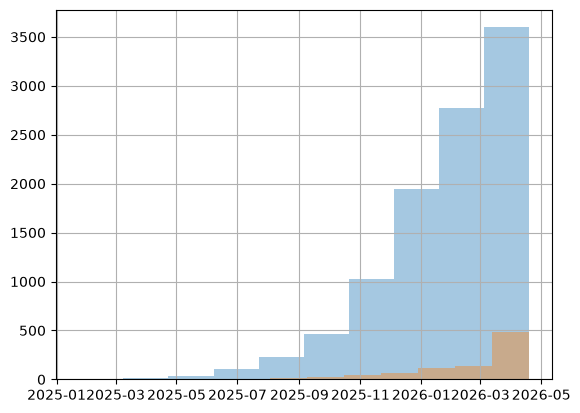

In [7]:
train.groupby('target')['cookie_created_at'].hist(alpha=0.4)
print('Распределение даты создания cookie по классам:')


---
- по дате начала окна:

Распределение даты создания cookie по классам:


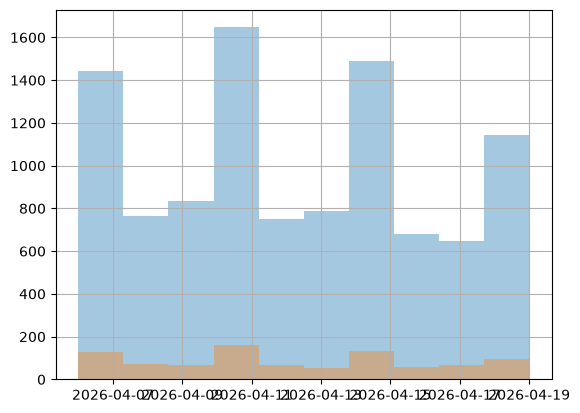

In [8]:
train.groupby('target')['window_start_ts'].hist(alpha=0.4)
print('Распределение даты создания cookie по классам:')


In [9]:
print('Первая куки в train создана', train['window_start_ts'].min())
print('Последняя куки в train создана', train['window_start_ts'].max())


Первая куки в train создана 2026-04-06 00:00:00
Последняя куки в train создана 2026-04-19 00:00:00


In [10]:
(train['window_end_ts'] - train['window_start_ts']).value_counts()


1 days    11091
Name: count, dtype: int64

**Выводы по временны́м признакам:**
* Распределение даты создания куки (`cookie_created_at`) у ботов и реальных пользователей имеет схожую форму (с ростом плотности к более свежим датам), поэтому сам по себе возраст куки не позволяет тривиально разделить классы.
* Окна наблюдения в `train` начинаются в период с **6 по 19 апреля 2026 года**, при этом соотношение ботов и людей остаётся достаточно стабильным на всём временном интервале.
* Длительность окна наблюдения (`window_end_ts - window_start_ts`) строго фиксирована и составляет ровно **24 часа (1 сутки)** для всех наблюдений.

## Анализ датафрейма `events`

### Распределение категориальных признаков:

---
- `event_name` - тип события
- `platform` - платформа пользователя
- `user_agent` - метаданные клиента

In [11]:
print(events.event_name.value_counts(), '\n')
print(events.platform.value_counts(), '\n')
print(events.user_agent.value_counts().iloc[[0, 1, 2, -2, -1]], '\n')


event_name
item_view               120817
search_results_view     100402
photo_swipe              36517
favorite_add             19049
seller_page_view         17403
contact_phone_show       11316
captcha_shown             7928
login                     6267
contact_chat_open         6125
contact_message_sent      3081
Name: count, dtype: int64 

platform
web        138792
android    126875
desktop     46866
ios         12269
iphone       4103
Name: count, dtype: int64 

user_agent
mozilla/5.0 (windows nt 10.0; win64; x64) applewebkit/537.36 (khtml, like gecko) chrome/119.0.0.0 yabrowser/23.11.0.0 safari/537.36    3737
mozilla/5.0 (windows nt 10.0; win64; x64; rv:119.0) gecko/20100101 firefox/119.0                                                       3670
mozilla/5.0 (windows nt 10.0; win64; x64) applewebkit/537.36 (khtml, like gecko) chrome/117.0.0.0 yabrowser/23.9.0.0 safari/537.36     3664
mozilla/5.0 (linux; android 12; sm-g991b) applewebkit/537.36 (khtml, like gecko) chrome/124.0

---
- `item_category` - категория объявления
- `item_location` - город
- `seller_type` - тип продавца

In [12]:
print(events.item_category.value_counts(), '\n')
print(events.item_location.value_counts().iloc[[0, 1, 2, -2, -1]], '\n')
print(events.seller_type.value_counts(), '\n')


item_category
avtomobili           20822
mebel                20541
bytovaya_tehnika     20161
hobbi                20020
elektronika          20002
uslugi               19869
odezhda              19846
kvartiry_arenda      19713
kvartiry_prodazha    19709
noutbuki             19583
detskie_tovary       19441
rabota               19387
telefony             19349
zhivotnye            19109
zapchasti            18433
Name: count, dtype: int64

 

item_location
sankt-peterburg    39221
novosibirsk        37989
moskva             37964
irkutsk             3949
samara              3886
Name: count, dtype: int64 

seller_type
private    112631
pro         82421
default     19256
Name: count, dtype: int64 



---
- `search_query` - поисковый запрос (только для события `search_results_view`)

In [13]:
events.search_query.value_counts()


search_query
toyota camry              919
кофемашина                919
клининг                   918
renault logan             916
kia rio 2019              908
                         ... 
стартер                   764
аккумулятор               761
samsung s23               757
macbook air m1            754
снять квартиру у метро    742
Name: count, Length: 120, dtype: int64

**Выводы по категориальным признакам `events`:**
* В логах зафиксировано **10 типов событий** (`event_name`). Большую часть трафика формируют просмотры карточек (`item_view` - 120.8 тыс.) и поисковой выдачи (`search_results_view` - 100.4 тыс.), тогда как целевые действия (отправка сообщений `contact_message_sent`, открытие чата `contact_chat_open`, авторизация `login`, показ капчи `captcha_shown`) встречаются значительно реже.
* События поступают с **5 платформ** (`web`, `android`, `desktop`, `ios`, `iphone`).
* В поле `user_agent` наряду со стандартными мобильными и десктопными браузерами уже на этапе первичного осмотра обнаруживаются явные сигнатуры автоматизированных HTTP-клиентов и парсеров (`python-requests`, `curl`, `scrapy` и др.).
* Категории товаров (`item_category`, 15 значений) распределены практически равномерно (~18–20 тыс. событий на категорию), типы продавцов (`seller_type`) с учётом выделенной при предобработке категории по умолчанию делятся на `private` (112.6 тыс.), `pro` (82.4 тыс.) и `default` (19.3 тыс.), а поисковые запросы (`search_query`) представлены фиксированным словарём из 120 фраз (осмелюсь предположить, что именно по ним с учетом временного окна производилась выгрузка).

### Доля пропусков:

In [14]:
print('пропуски по колонкам:')
print(events.isna().mean().round(3))


пропуски по колонкам:
cookie_id        0.000
event_ts         0.000
eid              0.000
event_name       0.000
platform         0.000
user_agent       0.000
item_id          0.348
item_category    0.100
item_location    0.072
seller_type      0.348
search_query     0.695
search_page      0.695
pointer_x        0.670
pointer_y        0.670
dtype: float64


### Анализ источников пропусков:

---
1) `pointer_x` / `pointer_y` по типам событий
2) `search_query` / `search_page` по типам событий

In [15]:
print('все типы событий:', sorted(events['event_name'].unique()), '\n')

print('доля событий с непустым значением pointer_x:')
print(
    events[~events['pointer_x'].isna()]['event_name'].value_counts()
    / events['event_name'].value_counts(),
    '\n',
)
print('доля событий с непустым значением search_query:')
print(
    (
        events[~events['search_query'].isna()]['event_name'].value_counts()
        / events['event_name'].value_counts()
    ).dropna(),
    '\n',
)


все типы событий: ['captcha_shown', 'contact_chat_open', 'contact_message_sent', 'contact_phone_show', 'favorite_add', 'item_view', 'login', 'photo_swipe', 'search_results_view', 'seller_page_view'] 

доля событий с непустым значением pointer_x:
event_name
captcha_shown           0.272200
contact_chat_open       0.308245
contact_message_sent    0.322623
contact_phone_show      0.323259
favorite_add            0.349467
item_view               0.326568
login                   0.353439
photo_swipe             0.341923
search_results_view     0.330462
seller_page_view        0.336149
Name: count, dtype: float64 

доля событий с непустым значением search_query:


event_name
search_results_view    1.0
Name: count, dtype: float64 



---
3) `item_id` по типам событий
4) `seller_type` по типам событий

In [16]:
print('все типы событий:', sorted(events['event_name'].unique()), '\n')

print('доля событий с непустым значением item_id:')
print(
    (
        events[~events['item_id'].isna()]['event_name'].value_counts()
        / events['event_name'].value_counts()
    ).dropna(),
    '\n',
)
print('доля событий с непустым значением seller_type:')
print(
    (
        events[~events['seller_type'].isna()]['event_name'].value_counts()
        / events['event_name'].value_counts()
    ).dropna(),
    '\n',
)


все типы событий: ['captcha_shown', 'contact_chat_open', 'contact_message_sent', 'contact_phone_show', 'favorite_add', 'item_view', 'login', 'photo_swipe', 'search_results_view', 'seller_page_view'] 

доля событий с непустым значением item_id:


event_name
contact_chat_open       1.0
contact_message_sent    1.0
contact_phone_show      1.0
favorite_add            1.0
item_view               1.0
photo_swipe             1.0
seller_page_view        1.0
Name: count, dtype: float64 

доля событий с непустым значением seller_type:
event_name
contact_chat_open       1.0
contact_message_sent    1.0
contact_phone_show      1.0
favorite_add            1.0
item_view               1.0
photo_swipe             1.0
seller_page_view        1.0
Name: count, dtype: float64 



---
5) `item_category` по типам событий
6) `item_location` по типам событий

In [17]:
print('все типы событий:', sorted(events['event_name'].unique()), '\n')

print('доля событий с непустым значением item_category:')
print(
    (
        events[~events['item_category'].isna()]['event_name'].value_counts()
        / events['event_name'].value_counts()
    ).dropna(),
    '\n',
)
print('доля событий с непустым значением item_location:')
print(
    (
        events[~events['item_location'].isna()]['event_name'].value_counts()
        / events['event_name'].value_counts()
    ).dropna(),
    '\n',
)


все типы событий: ['captcha_shown', 'contact_chat_open', 'contact_message_sent', 'contact_phone_show', 'favorite_add', 'item_view', 'login', 'photo_swipe', 'search_results_view', 'seller_page_view'] 

доля событий с непустым значением item_category:
event_name
contact_chat_open       0.941224
contact_message_sent    0.938656
contact_phone_show      0.941234
favorite_add            0.936637
item_view               0.940654
photo_swipe             0.941753
search_results_view     0.940340
seller_page_view        0.941562
Name: count, dtype: float64 

доля событий с непустым значением item_location:
event_name
contact_chat_open       0.969306
contact_message_sent    0.971113
contact_phone_show      0.971456
favorite_add            0.972072
item_view               0.969756
photo_swipe             0.968261
search_results_view     0.969005
seller_page_view        0.968913
Name: count, dtype: float64 



**Выводы по структуре пропусков в `events`:**
Пропуски в логах имеют не случайный, а **структурный (логический) характер**, обусловленный типом конкретного события:
1. Параметры поиска (`search_query`, `search_page` - 69.5% пропусков) заполняются в 100% случаев **только** для события `search_results_view` и отсутствуют во всех остальных типах событий.
2. Координаты указателя (`pointer_x`, `pointer_y` - 67.0% пропусков) фиксируются примерно в 27–35% случаев равномерно по всем типам событий.
3. Идентификатор карточки `item_id` и тип продавца `seller_type` (по 34.8% NaN после замены пропусков в карточках на категорию `default`) заполнены в **100%** событий взаимодействия с конкретным объявлением или продавцом (`item_view`, `photo_swipe`, `favorite_add`, `seller_page_view`, `contact_*`) и закономерно пусты при поиске, логине и показе капчи.
4. Категория и локация (`item_category` - 10.0% NaN, `item_location` - 7.2% NaN) заполнены почти во всех контентных и поисковых событиях (94–97%) и полностью отсутствуют только в технических событиях `login` и `captcha_shown`.

Следовательно, агрегировать эти признаки необходимо с учётом их области определения (например, считать статистики по страницам поиска только по непустым значениям или нормировать счётчики на количество релевантных событий).

## Конструирование датафреймов `ev_tr` и `ev_te`

Соединим датафреймы `train` и `test` с датафреймом `events` по `cookie_id` с учетом ограничения: `window_start_ts <= event_ts < window_end_ts` для анализа и последующей агрегации событийных признаков.

In [18]:
def events_in_window(events, meta, include_target=False):
    meta_atributes = ['cookie_id', 'window_start_ts', 'window_end_ts']
    if include_target:
        meta_atributes += ['target']
    ev = events.merge(meta[meta_atributes], on='cookie_id')
    return ev[(ev.event_ts >= ev.window_start_ts) & (ev.event_ts < ev.window_end_ts)]


ev_tr = events_in_window(events, train, include_target=True)
ev_te = events_in_window(events, test)
print(len(ev_tr), len(ev_te))
print(ev_tr['target'].mean().round(3))


198436 89690
0.134


## Анализ датафреймов `ev_tr` и `ev_te`

### Проверка качества датафреймов (учет ограничений окна):

In [19]:
print(
    'Для каждой записи в train есть зарегистрированные события в окне:',
    len(ev_tr['cookie_id'].unique()) == len(train),
)
print(
    'Для каждой записи в test есть зарегистрированные события в окне:',
    len(ev_te['cookie_id'].unique()) == len(test),
)


Для каждой записи в train есть зарегистрированные события в окне: True
Для каждой записи в test есть зарегистрированные события в окне: True


In [20]:
ev_tr.info()


<class 'pandas.DataFrame'>
Index: 198436 entries, 0 to 239214
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   cookie_id        198436 non-null  str           
 1   event_ts         198436 non-null  datetime64[us]
 2   eid              198436 non-null  int64         
 3   event_name       198436 non-null  str           
 4   platform         198436 non-null  str           
 5   user_agent       198436 non-null  str           
 6   item_id          132819 non-null  float64       
 7   item_category    182802 non-null  str           
 8   item_location    188610 non-null  str           
 9   seller_type      132819 non-null  str           
 10  search_query     61717 non-null   str           
 11  search_page      61717 non-null   float64       
 12  pointer_x        66243 non-null   float64       
 13  pointer_y        66243 non-null   float64       
 14  window_start_ts  198436 non-null  da

**Выводы после фильтрации событий по окну наблюдения `[window_start_ts, window_end_ts)`:**
* По условию задачи классификация должна опираться только на события внутри заданного 24-часового окна. После фильтрации объём выборки составил **198 436** событий в `ev_tr` и **89 690** событий в `ev_te`.
* У каждой куки из `train` и `test` внутри выделенного окна осталось хотя бы одно событие (потерь сессий нет).
* Доля событий, сгенерированных ботами в `ev_tr`, составляет **13.4%**, что заметно выше доли самих ботов в `train` (**8.11%**). Это сразу указывает на то, что в среднем за сутки бот генерирует существенно больше событий, чем обычный пользователь.

### Не представленные в `ev_tr` категориальные значения:

In [21]:
ev_tr.info()


<class 'pandas.DataFrame'>
Index: 198436 entries, 0 to 239214
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   cookie_id        198436 non-null  str           
 1   event_ts         198436 non-null  datetime64[us]
 2   eid              198436 non-null  int64         
 3   event_name       198436 non-null  str           
 4   platform         198436 non-null  str           
 5   user_agent       198436 non-null  str           
 6   item_id          132819 non-null  float64       
 7   item_category    182802 non-null  str           
 8   item_location    188610 non-null  str           
 9   seller_type      132819 non-null  str           
 10  search_query     61717 non-null   str           
 11  search_page      61717 non-null   float64       
 12  pointer_x        66243 non-null   float64       
 13  pointer_y        66243 non-null   float64       
 14  window_start_ts  198436 non-null  da

---
- `event_name`
- `platform`
- `user_agent`
- `item_category`
- `item_location`
- `seller_type`
- `search_query`

In [ ]:
print(
    'Каждое значение event_name из ev_te представлено в ev_tr:',
    np.isin(ev_te['event_name'].unique(), ev_tr['event_name'].unique()).all(),
    '\n',
)

print(
    f'Всего уникальных значений event_name в events: {len(events["event_name"].unique())}'
)
print(
    f'Всего уникальных значений event_name в ev_tr: {len(ev_tr["event_name"].unique())}',
    '\n',
    f'Недостающие значения: {set.difference(set(events["event_name"].unique()), ev_tr["event_name"].unique())}',
)
print(
    f'Всего уникальных значений event_name в ev_te: {len(ev_te["event_name"].unique())}',
    '\n',
    f'Недостающие значения: {set.difference(set(events["event_name"].unique()), ev_te["event_name"].unique())}',
    '\n',
)

print(
    'Каждое значение platform из ev_te представлено в ev_tr:',
    np.isin(ev_te['platform'].unique(), ev_tr['platform'].unique()).all(),
    '\n',
)
print(
    'Каждое значение user_agent из ev_te представлено в ev_tr:',
    np.isin(ev_te['user_agent'].unique(), ev_tr['user_agent'].unique()).all(),
)

print(
    'Каждое значение item_category из ev_te представлено в ev_tr:',
    np.isin(
        ev_te['item_category'].dropna().unique(),
        ev_tr['item_category'].dropna().unique(),
    ).all(),
    '\n',
)

print(
    'Каждое значение item_location из ev_te представлено в ev_tr:',
    np.isin(
        ev_te['item_location'].dropna().unique(),
        ev_tr['item_location'].dropna().unique(),
    ).all(),
    '\n',
)

print(
    'Каждое значение seller_type из ev_te представлено в ev_tr:',
    np.isin(
        ev_te['seller_type'].dropna().unique(), ev_tr['seller_type'].dropna().unique()
    ).all(),
    '\n',
)

print(
    'Каждое значение search_query из ev_te представлено в ev_tr:',
    np.isin(
        ev_te['search_query'].dropna().unique(), ev_tr['search_query'].dropna().unique()
    ).all(),
    '\n',
)


Каждое значение event_name из ev_te представлено в ev_tr: True 

Всего уникальных значений event_name в events: 10
Всего уникальных значений event_name в ev_tr: 9 
 Недостающие значения: {'captcha_shown'}
Всего уникальных значений event_name в ev_te: 9

 
 Недостающие значения: {'captcha_shown'} 

Каждое значение platform из ev_te представлено в ev_tr: True 

Каждое значение user_agent из ev_te представлено в ev_tr: True
Каждое значение item_category из ev_te представлено в ev_tr: True 

Каждое значение item_location из ev_te представлено в ev_tr: True 

Каждое значение seller_type из ev_te представлено в ev_tr: True 

Каждое значение search_query из ev_te представлено в ev_tr: True 



**Выводы по согласованности категорий между `ev_tr` и `ev_te`:**
* В тестовых событиях `ev_te` нет ни одного нового (ранее не встречавшегося в `ev_tr`) значения среди категориальных признаков (`event_name`, `platform`, `user_agent`, `item_category`, `item_location`, `seller_type`, `search_query`).
* **Важное наблюдение:** после фильтрации по окну `[window_start_ts, window_end_ts)` из обеих выборок (`ev_tr` и `ev_te`) полностью исчезло событие `captcha_shown` (осталось 9 уникальных типов событий из 10). Все показы капчи в исходном логе происходили за пределами анализируемых окон наблюдения, поэтому использовать `captcha_shown` в качестве признака внутри окна не имеет смысла.

### Распределение таргета по категориальным признакам:

---
- `user_agent`

In [23]:
mean_label_by_agents = ev_tr.groupby('user_agent')['target'].mean()

mean_label_by_agents[mean_label_by_agents > 0.3]


user_agent
avito/118.0 (android 11; m2101k6g) okhttp/4.11.0                                                                         0.446309
curl/8.1.2                                                                                                               0.383055
go-http-client/1.1                                                                                                       0.367372
mozilla/5.0 (macintosh; intel mac os x 10_15_7) applewebkit/537.36 (khtml, like gecko) chrome/122.0.0.0 safari/537.36    0.301066
mozilla/5.0 (x11; linux x86_64) applewebkit/537.36 (khtml, like gecko) headlesschrome/114.0.0.0 safari/537.36            0.495474
mozilla/5.0 (x11; linux x86_64) applewebkit/537.36 (khtml, like gecko) headlesschrome/118.0.0.0 safari/537.36            0.578972
mozilla/5.0 (x11; linux x86_64) applewebkit/537.36 (khtml, like gecko) headlesschrome/120.0.0.0 safari/537.36            0.494769
mozilla/5.0 (x11; linux x86_64) applewebkit/537.36 (khtml, like gecko) headless

---
- `event_name`

In [24]:
mean_label_by_event = ev_tr.groupby('event_name')['target'].mean()

mean_label_by_event[(mean_label_by_event < 0.06) | (mean_label_by_event > 0.15)]


event_name
favorite_add           0.059816
item_view              0.155614
login                  0.053077
search_results_view    0.150979
Name: target, dtype: float64

---
- `platform`

In [25]:
mean_label_by_platform = ev_tr.groupby('platform')['target'].mean()

mean_label_by_platform


platform
android    0.079586
desktop    0.179824
ios        0.052833
iphone     0.053420
web        0.179399
Name: target, dtype: float64

---
- `seller_type`

In [ ]:
mean_label_by_seller = ev_tr.groupby('seller_type')['target'].mean()

print(mean_label_by_seller, '\n')
print(f'for NaN: {ev_tr[ev_tr["seller_type"].isna()]["target"].mean()}')


seller_type
default    0.124657
private    0.120696
pro        0.138396
Name: target, dtype: float64 

for NaN: 0.14516055290549706


---
- `search_query`

In [27]:
mean_label_by = ev_tr.groupby('search_query')['target'].mean()

mean_label_by[mean_label_by > 0.19]


search_query
hyundai solaris      0.193424
skoda octavia        0.211470
автокресло           0.201629
грузоперевозки       0.236994
джинсы levis         0.203735
микроволновка        0.214567
мультиварка          0.195029
наушники airpods     0.197652
новостройка          0.199637
работа водителем     0.191901
работа грузчиком     0.197368
самокат взрослый     0.201536
смена 12 часов       0.197842
снять 1к квартиру    0.194231
удаленная работа     0.218750
Name: target, dtype: float64

**Выводы по связи категориальных признаков с таргетом:**
* **`user_agent` - сильнейший индикатор автоматизации:** для скриптовых библиотек и headless-браузеров (`curl`, `go-http-client`, `node-fetch`, `python-requests`, `python-urllib3`, `scrapy`, `headlesschrome`) доля ботов на уровне событий достигает **30–58%** (при среднем уровне 13.4%). Поэтому выделение бинарного флага скриптового User-Agent (`script_ua`) и проверка несоответствия между `platform` и `user_agent` (`client_metadata_conflict`) дают мощный разделяющий сигнал.
* **Тип события (`event_name`):** боты непропорционально часто совершают пассивный парсинг (`item_view` - 15.6%, `search_results_view` - 15.1%, `seller_page_view` - 12.1%) и значительно реже выполняют действия, свойственные реальным покупателям (`login` - 5.3%, `favorite_add` - 6.0%, `photo_swipe` - 7.6%).
* **Платформа (`platform`):** активность ботов сконцентрирована на десктопных и веб-платформах (`desktop` - 18.0%, `web` - 17.9%), тогда как в мобильных клиентах (`android` - 8.0%, `iphone` и `ios` - по 5.3%) доля ботов кратно ниже.
* **Тип продавца и поисковые запросы:** среди событий с карточками доля ботов выше у профессиональных продавцов (`pro` - 13.8%), чем у продавцов категории по умолчанию (`default` - 12.5%) и частных объявлений (`private` - 12.1%), а в событиях без продавца (`NaN` - в основном поиск) она достигает 14.5%. Среди поисковых запросов также выделяются отдельные коммерческие фразы с повышенной долей ботов (до 20–24%).

### Распределение простейших агрегированных признаков:

In [28]:
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns

desktop_script_user_agents = [
    'curl/8.1.2',
    'go-http-client/1.1',
    'node-fetch/3.3.2',
    'python-requests/2.31.0',
    'python-urllib3/2.0.7',
    'scrapy/2.11.0',
]
platform_ua_conflict_markers = {
    'android': ['iphone', 'ipad', 'windows', 'macintosh'] + desktop_script_user_agents,
    'ios': ['android', 'windows', 'linux', 'chrome'] + desktop_script_user_agents,
    'iphone': ['android', 'windows', 'linux'] + desktop_script_user_agents,
    'desktop': ['android', 'iphone', 'ipad'],
    'web': [],
}


In [29]:
ev_tr_random_aggs = (
    ev_tr.sort_values('event_ts')
    .groupby(['target', 'cookie_id'])
    .agg(
        count=('event_ts', 'count'),
        common_event=('event_name', lambda x: x.mode().iat[0]),
        common_platform=('platform', lambda x: x.mode().iat[0]),
        common_user_agent=('user_agent', lambda x: x.mode().iat[0]),
        script_ua=(
            'user_agent',
            lambda x: np.isin(desktop_script_user_agents, x).any(),
        ),
        nunique_items=('item_id', 'nunique'),
        item_events=('item_id', lambda x: (~x.isna()).sum()),
        item_view_times=('event_name', lambda x: (x == 'item_view').sum()),
        search_times=('event_name', lambda x: (x == 'search_results_view').sum()),
        photo_swipe_times=('event_name', lambda x: (x == 'photo_swipe').sum()),
        favorite_add_times=('event_name', lambda x: (x == 'favorite_add').sum()),
        seller_view_times=('event_name', lambda x: (x == 'seller_page_view').sum()),
        login_times=('event_name', lambda x: (x == 'login').sum()),
        contact_show_times=('event_name', lambda x: (x == 'contact_phone_show').sum()),
        chat_open_times=('event_name', lambda x: (x == 'contact_chat_open').sum()),
        message_sent_times=(
            'event_name',
            lambda x: (x == 'contact_message_sent').sum(),
        ),
        nunique_cats=('item_category', 'nunique'),
        loc_max_freq=(
            'item_location',
            lambda x: (
                Counter(x[~x.isna()]).most_common(1)[0][1] / ((~x.isna()).sum() + 1)
                if (~x.isna()).any()
                else 0
            ),
        ),
        seller_type_pro=('seller_type', lambda x: (x == 'pro').any()),
        seller_type_private=('seller_type', lambda x: (x == 'private').any()),
        seller_type_default=('seller_type', lambda x: (x == 'default').any()),
        seller_page_view_first=(
            'event_name',
            lambda x: x.iloc[0] == 'seller_page_view',
        ),
        search_page_max=('search_page', 'max'),
        search_page_first=(
            'search_page',
            lambda x: x[~x.isna()].iloc[0].item() if (~x.isna()).any() else 0,
        ),  # groupby preserves the order of rows within each group
        nunique_search_query=('search_query', 'nunique'),
        pointer_x_max_freq=(
            'pointer_x',
            lambda x: (
                Counter(x[~x.isna()]).most_common(1)[0][1] if (~x.isna()).any() else 0
            ),
        ),
        pointer_y_max_freq=(
            'pointer_y',
            lambda x: (
                Counter(x[~x.isna()]).most_common(1)[0][1] if (~x.isna()).any() else 0
            ),
        ),
        # switches_platform=('platform', lambda x: x.nunique() > 1),
        # switches_agent=('user_agent', lambda x: x.nunique() > 1),
    )
    .reset_index()
)

ev_tr_random_aggs.loc[
    ev_tr_random_aggs['search_page_max'].isna(), 'search_page_max'
] = 0

ev_tr_random_aggs['item_events_per_unique_item'] = ev_tr_random_aggs['item_events'] / (
    ev_tr_random_aggs['nunique_items'] + 1
)
ev_tr_random_aggs['contact_show_times_per_unique_item'] = ev_tr_random_aggs[
    'contact_show_times'
] / (ev_tr_random_aggs['nunique_items'] + 1)
ev_tr_random_aggs['photo_swipe_per_unique_item'] = ev_tr_random_aggs[
    'photo_swipe_times'
] / (ev_tr_random_aggs['nunique_items'] + 1)
# ev_tr_random_aggs['changes_client_metadata'] = ev_tr_random_aggs['switches_platform'] | ev_tr_random_aggs['switches_agent']

ev_tr_random_aggs['search_per_item_view'] = ev_tr_random_aggs['search_times'] / (
    ev_tr_random_aggs['item_view_times'] + 1
)
ev_tr_random_aggs['seller_view_per_item_view'] = ev_tr_random_aggs[
    'seller_view_times'
] / (ev_tr_random_aggs['item_view_times'] + 1)

ev_tr_random_aggs['message_sent_per_chat_open'] = ev_tr_random_aggs[
    'message_sent_times'
] / (ev_tr_random_aggs['chat_open_times'] + 1)

ev_tr_random_aggs['forbidden_ua_substrings'] = ev_tr_random_aggs['common_platform'].map(
    platform_ua_conflict_markers
)
ev_tr_random_aggs['client_metadata_conflict'] = [
    any(sub in text for sub in forbidden)
    for text, forbidden in zip(
        ev_tr_random_aggs['common_user_agent'],
        ev_tr_random_aggs['forbidden_ua_substrings'],
    )
]


ev_tr_random_aggs = ev_tr_random_aggs.drop(
    [
        'common_platform',
        'common_user_agent',
        'item_events',
        'item_view_times',
        'search_times',
        'photo_swipe_times',
        'contact_show_times',
        'message_sent_times',
        'forbidden_ua_substrings',
    ],
    axis=1,
)

ev_tr_random_aggs.info()


<class 'pandas.DataFrame'>
RangeIndex: 11091 entries, 0 to 11090
Data columns (total 28 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   target                              11091 non-null  int64  
 1   cookie_id                           11091 non-null  str    
 2   count                               11091 non-null  int64  
 3   common_event                        11091 non-null  str    
 4   script_ua                           11091 non-null  bool   
 5   nunique_items                       11091 non-null  int64  
 6   favorite_add_times                  11091 non-null  int64  
 7   seller_view_times                   11091 non-null  int64  
 8   login_times                         11091 non-null  int64  
 9   chat_open_times                     11091 non-null  int64  
 10  nunique_cats                        11091 non-null  int64  
 11  loc_max_freq                        11091 non-null  

<Axes: xlabel='count'>

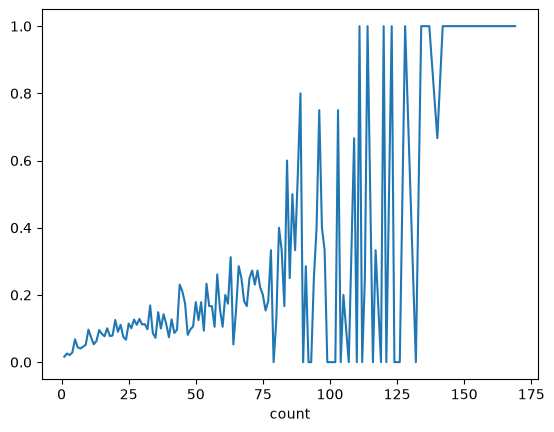

In [30]:
# ev_tr_random_aggs[ev_tr_random_aggs['count'] < 5]['target'].value_counts()

ev_tr_random_aggs.groupby('count')['target'].mean().plot()


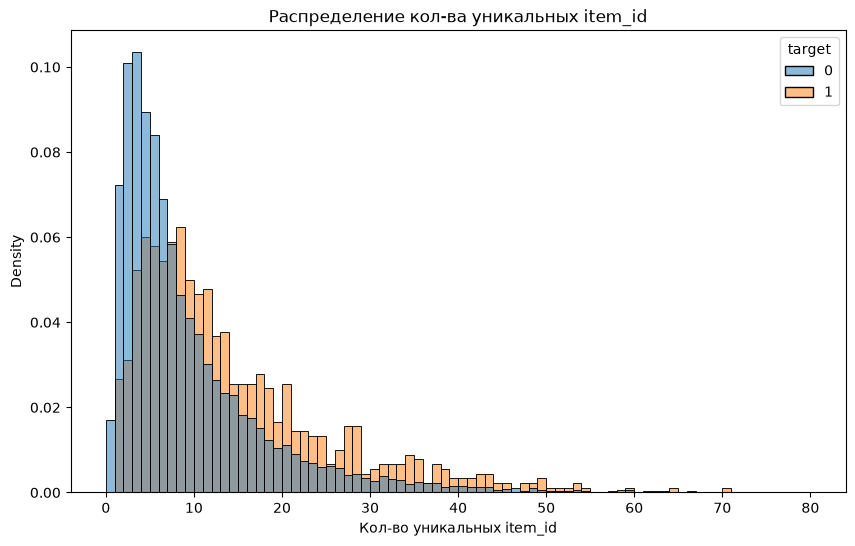

In [31]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='nunique_items',
    hue='target',
    bins=80,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.title('Распределение кол-ва уникальных item_id')
plt.xlabel('Кол-во уникальных item_id')
plt.show()


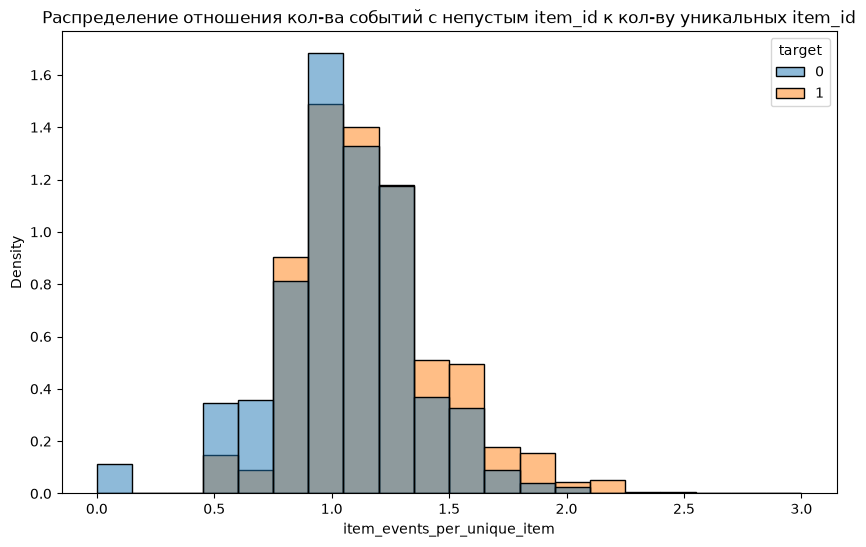

In [32]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='item_events_per_unique_item',
    hue='target',
    bins=20,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.title(
    'Распределение отношения кол-ва событий с непустым item_id к кол-ву уникальных item_id'
)
plt.show()


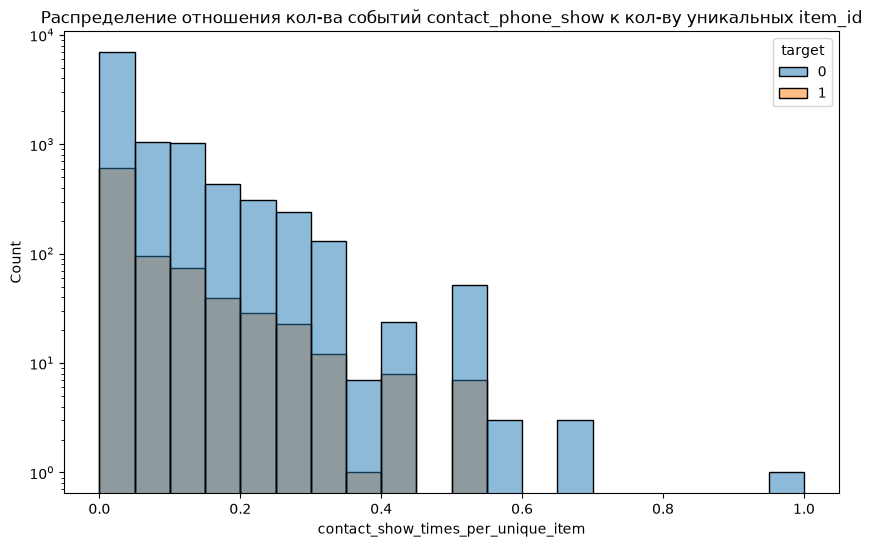

In [33]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='contact_show_times_per_unique_item',
    hue='target',
    bins=20,
    alpha=0.5,
)

plt.yscale('log')
plt.title(
    'Распределение отношения кол-ва событий contact_phone_show к кол-ву уникальных item_id'
)
plt.show()


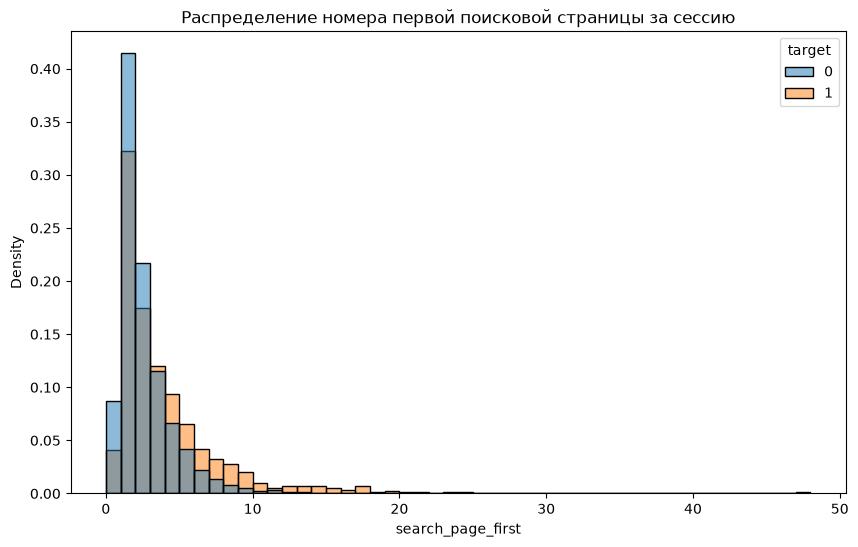

In [34]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='search_page_first',
    hue='target',
    bins=48,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.title('Распределение номера первой поисковой страницы за сессию')
plt.show()


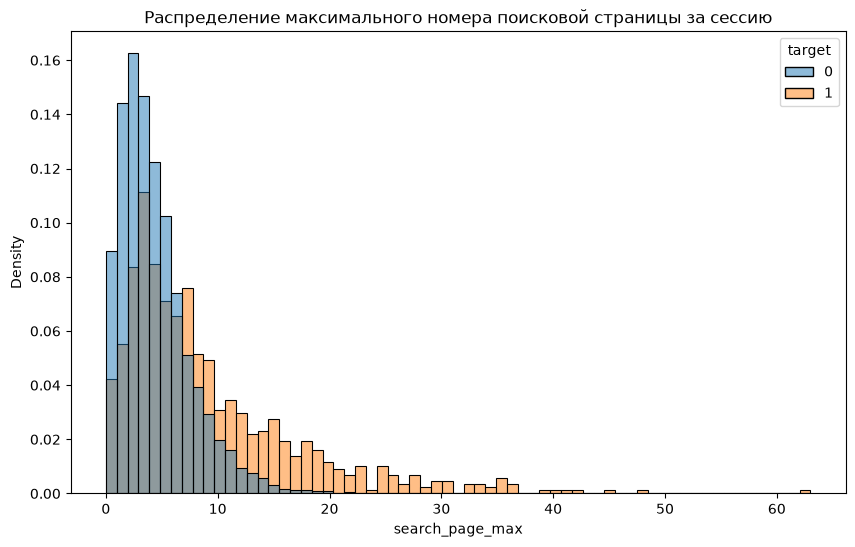

In [35]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='search_page_max',
    hue='target',
    bins=65,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.title('Распределение максимального номера поисковой страницы за сессию')
plt.show()


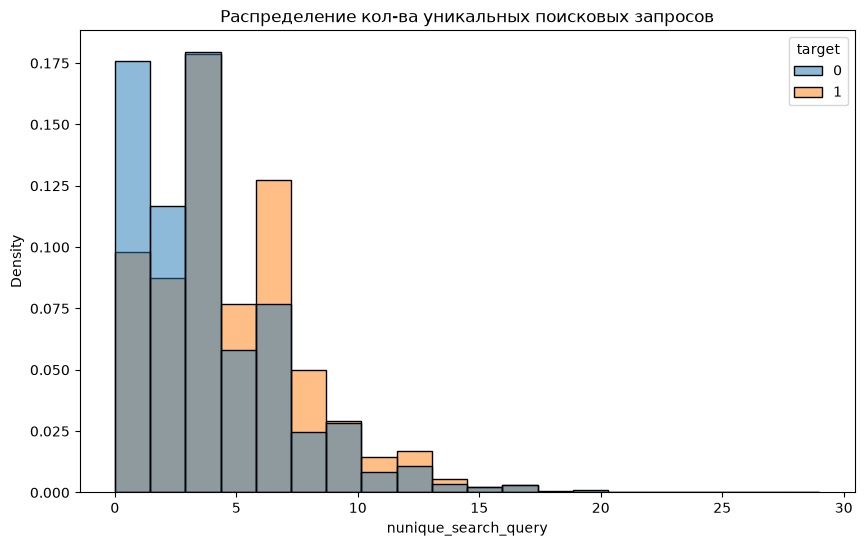

In [36]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='nunique_search_query',
    hue='target',
    bins=20,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.title('Распределение кол-ва уникальных поисковых запросов')
plt.show()


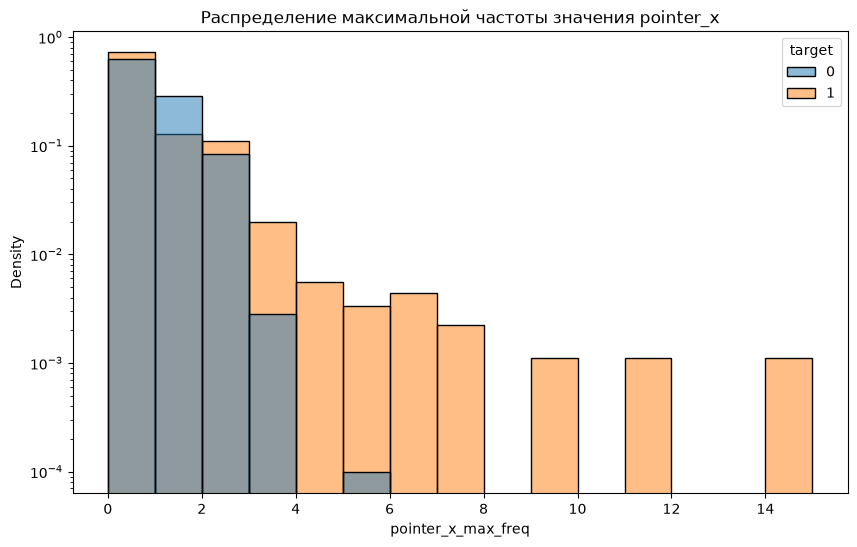

In [37]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='pointer_x_max_freq',
    hue='target',
    bins=15,
    binrange=(0, 15),
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('log')
plt.title('Распределение максимальной частоты значения pointer_x')
plt.show()


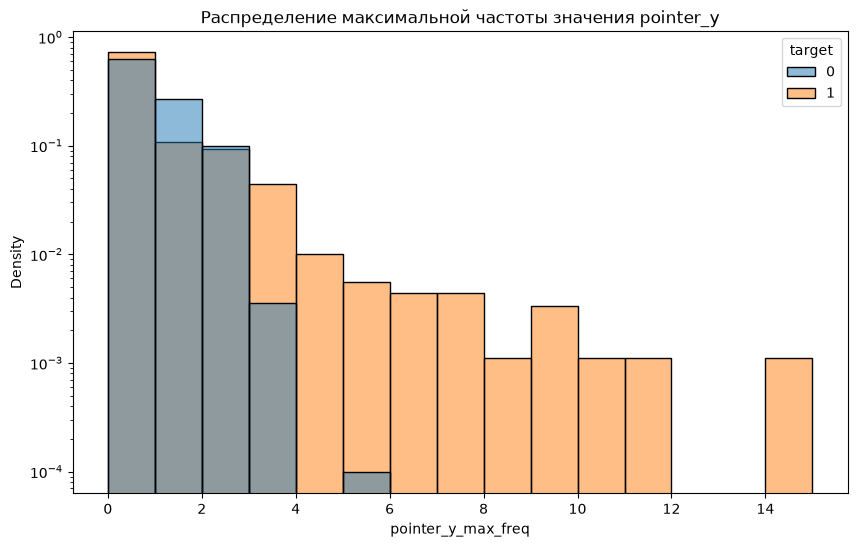

In [38]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ev_tr_random_aggs,
    x='pointer_y_max_freq',
    hue='target',
    bins=15,
    binrange=(0, 15),
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('log')
plt.title('Распределение максимальной частоты значения pointer_y')
plt.show()


**Выводы по поведенческим агрегатам сессии (по результатам анализа гистограмм):**
* **Общее число событий (`count`) и уникальных карточек (`nunique_items`):**
  * На нормированной гистограмме `count` доля ботов монотонно растёт вместе с активностью сессии: от `~2%` при `1–5` событиях до `~30–35%` при `70–80` событиях, а при **`count > 140` достигает 100%** (все сверхактивные сессии принадлежат ботам).
  * По числу уникальных карточек `nunique_items` реальные пользователи (`target = 0`) преобладают по плотности только на интервале `0–7` объявлений (пик на `2–4` карточках), тогда как начиная с **`nunique_items >= 8`** и на всём правом хвосте (вплоть до `70+` карточек) плотность распределения ботов стабильно выше.
* **Число взаимодействий с карточками на один уникальный товар (`item_events_per_unique_item = item_events / (nunique_items + 1)`):**
  * В точке `0.0` (сессии без событий с карточками), в диапазоне малых значений `[0.45, 0.75]` (просмотр 1–2 карточек по одному разу: `1/2 = 0.5`, `2/3 ≈ 0.67` из-за сглаживающей поправки `+ 1` в знаменателе) и в основной моде около `0.9–1.0` плотность выше у реальных пользователей (`target = 0`).
  * В правом же хвосте - при **`item_events_per_unique_item > 1.35` (вплоть до `2.25+`)** - плотность стабильно выше у **ботов (`target = 1`)**. Это означает, что вопреки интуитивному предположению об «однократном открытии страницы парсером», боты в среднем генерируют больше событий на одну уникальную карточку (за счёт большого числа карточек, нивелирующего `+ 1` в знаменателе, а также повторных обращений к одним и тем же объявлениям и связанным с ними действиям).
* **Просмотр контактов в пересчёте на уникальную карточку (`contact_show_times_per_unique_item = contact_show_times / (nunique_items + 1)`):**
  * На гистограмме (построенной в логарифмическом масштабе абсолютных частот `Count`) видно, что у **ботов (`target = 1`)** значения признака сосредоточены в левой части графика (**`0.0–0.35`**, единичные выбросы до **`0.55`**), тогда как область высоких значений (**`> 0.55` вплоть до `1.0`**) принадлежит **исключительно реальным пользователям (`target = 0`)**.
  * Причина кроется в знаменателе `(nunique_items + 1)`: боты просматривают десятки уникальных карточек за сессию, поэтому даже при наличии открытий контактов их удельная доля на одну карточку остаётся низкой (`<= 0.55`). Высокие же значения (`0.5–1.0`) возникают тогда, когда обычный покупатель целенаправленно открывает 1–2 объявления и в каждом из них запрашивает телефон (либо открывает контакты несколько раз на одной карточке).
* **Поведение в поиске (`search_page_first`, `search_page_max`, `nunique_search_query`):**
  * `search_page_first`: люди (`target = 0`) имеют более высокую плотность в `0` (сессии без поиска) и на стартовых страницах `1–2`. Начиная с **`search_page_first >= 3`** (и вплоть до страниц `20–48`) плотность ботов на порядок выше - парсеры часто начинают обход выдачи сразу с глубоких страниц пагинации.
  * `search_page_max`: реальные пользователи преобладают при глубине просмотра до `6`-й страницы включительно (`search_page_max <= 6`), тогда как при **`search_page_max >= 7`** (хвост до `60+` страниц) доминируют боты.
  * `nunique_search_query`: при малом числе поисковых запросов (`0–2` уникальных запроса за сессию) заметно преобладают реальные пользователи (`target = 0`), на уровне `3–4` запросов плотности классов сравниваются, а начиная с **`nunique_search_query >= 5`** (`5–15` различных запросов за сессию) наблюдается сильный перевес ботов (`target = 1`).
* **Повторяемость координат кликов (`pointer_x_max_freq`, `pointer_y_max_freq`):**
  * Реальные пользователи имеют более высокую плотность **только при `freq = 1`** (координаты кликов не повторяются). В `0` (отсутствие кликов с координатами) наблюдается небольшой перевес ботов, а при **`freq >= 3`** боты доминируют кратно; при **`freq >= 6`** (вплоть до `22` кликов в одну и ту же координату) реальные пользователи полностью исчезают и остаются исключительно боты.

### Распределение агрегированной разницы во времени между событиями:

In [39]:
ev_plus_diff = ev_tr.copy()

ev_plus_diff['time_diff'] = (
    ev_plus_diff.sort_values('event_ts')
    .groupby(['target', 'cookie_id'])['event_ts']
    .diff()
)
ev_plus_diff['time_diff'] = ev_plus_diff['time_diff'].dt.total_seconds()

ev_plus_diff.sort_values('event_ts').head(3)


,cookie_id,event_ts,eid,event_name,platform,user_agent,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y,window_start_ts,window_end_ts,target,time_diff
160932,ck_cfe25807d8b6fd01,2026-04-06 00:02:57,200,item_view,desktop,mozilla/5.0 (macintosh; intel mac os x 10_15_7...,1029019.0,zhivotnye,astrahan,pro,NaN,NaN,1079.0,492.0,2026-04-06,2026-04-07,1,NaN
223115,ck_cfe25807d8b6fd01,2026-04-06 00:03:07,100,search_results_view,web,mozilla/5.0 (macintosh; intel mac os x 10_15_7...,NaN,zhivotnye,ekaterinburg,NaN,котята,2.0,1059.0,483.0,2026-04-06,2026-04-07,1,10.0
149037,ck_cfe25807d8b6fd01,2026-04-06 00:03:22,100,search_results_view,web,mozilla/5.0 (macintosh; intel mac os x 10_15_7...,NaN,zhivotnye,sankt-peterburg,NaN,котята,1.0,1061.0,494.0,2026-04-06,2026-04-07,1,15.0


In [40]:
diffs_stats = (
    ev_plus_diff.groupby(['cookie_id', 'target'])
    .agg(
        count=('event_ts', 'count'),
        time_diff_min=('time_diff', 'min'),
        time_diff_mean=('time_diff', 'mean'),
        time_diff_median=('time_diff', 'median'),
        time_diff_std=('time_diff', 'std'),
        time_diff_nunique=('time_diff', 'nunique'),
        time_diff_max_freq=('time_diff', lambda x: Counter(x).most_common(1)[0][1]),
    )
    .reset_index()
)
diffs_stats.loc[
    diffs_stats['count'] == 1, ['time_diff_nunique', 'time_diff_max_freq']
] = 0
diffs_stats.loc[
    diffs_stats['count'] == 1,
    ['time_diff_min', 'time_diff_mean', 'time_diff_median', 'time_diff_std'],
] = -1
diffs_stats.loc[diffs_stats['time_diff_std'].isna(), 'time_diff_std'] = -1

diffs_stats.info()


<class 'pandas.DataFrame'>
RangeIndex: 11091 entries, 0 to 11090
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cookie_id           11091 non-null  str    
 1   target              11091 non-null  int64  
 2   count               11091 non-null  int64  
 3   time_diff_min       11091 non-null  float64
 4   time_diff_mean      11091 non-null  float64
 5   time_diff_median    11091 non-null  float64
 6   time_diff_std       11091 non-null  float64
 7   time_diff_nunique   11091 non-null  int64  
 8   time_diff_max_freq  11091 non-null  int64  
dtypes: float64(4), int64(4), str(1)
memory usage: 780.0 KB


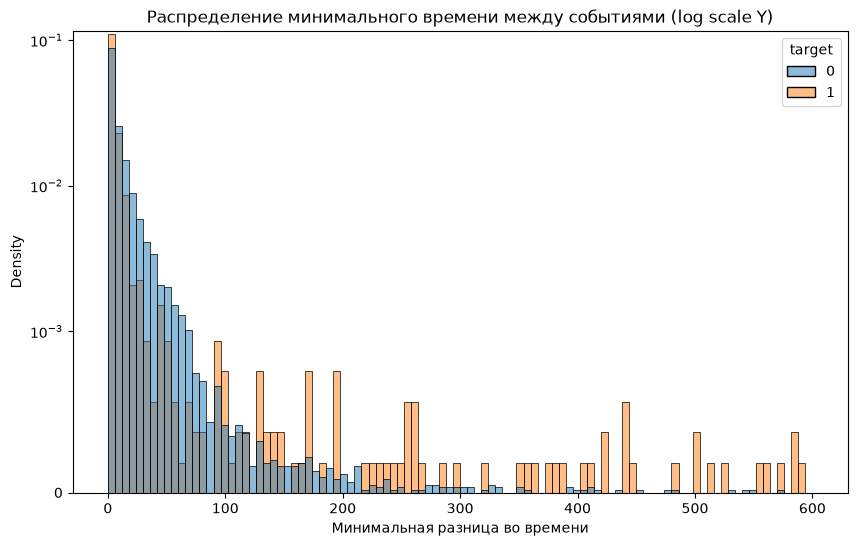

In [41]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=diffs_stats,
    x='time_diff_min',
    hue='target',
    bins=100,
    binrange=(0, 600),
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('symlog', linthresh=0.001)
plt.title('Распределение минимального времени между событиями (log scale Y)')
plt.xlabel('Минимальная разница во времени')
plt.show()


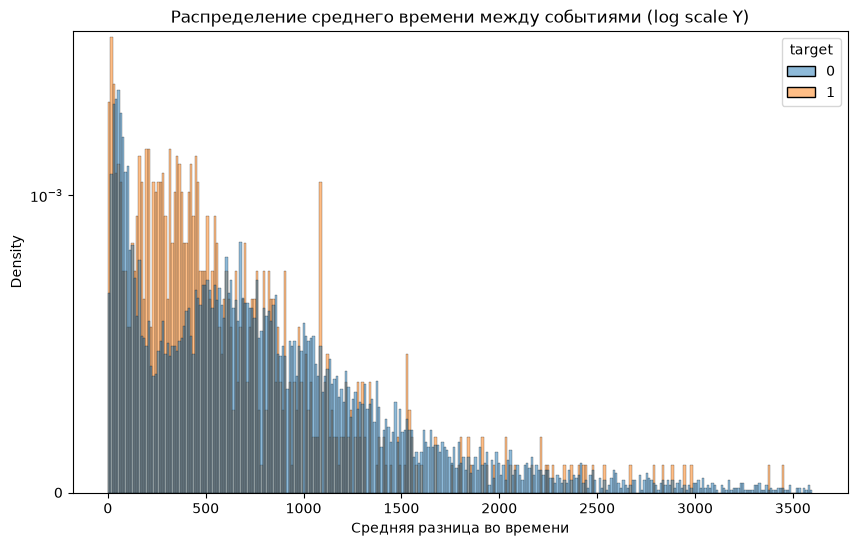

In [42]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=diffs_stats,
    x='time_diff_mean',
    hue='target',
    bins=300,
    binrange=(0, 3600),
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('symlog', linthresh=0.001)
plt.title('Распределение среднего времени между событиями (log scale Y)')
plt.xlabel('Средняя разница во времени')
plt.show()


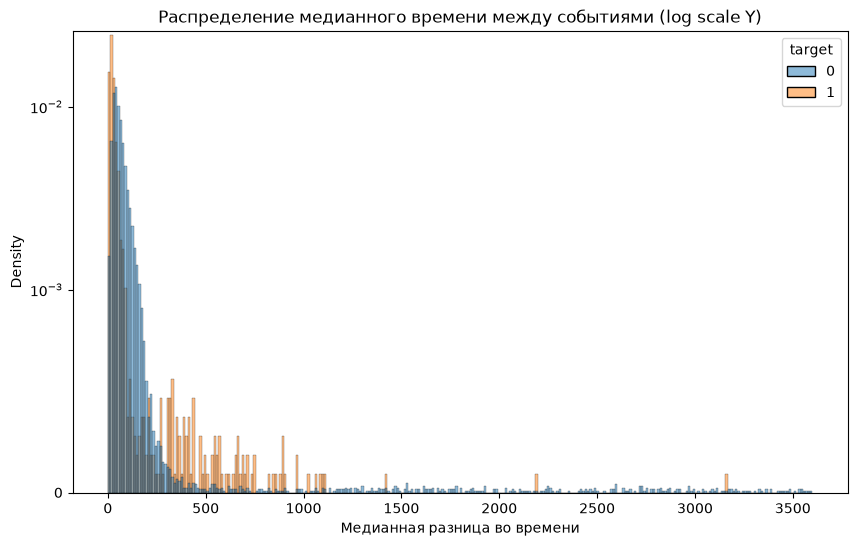

In [43]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=diffs_stats,
    x='time_diff_median',
    hue='target',
    bins=300,
    binrange=(0, 3600),
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('symlog', linthresh=0.001)
plt.title('Распределение медианного времени между событиями (log scale Y)')
plt.xlabel('Медианная разница во времени')
plt.show()


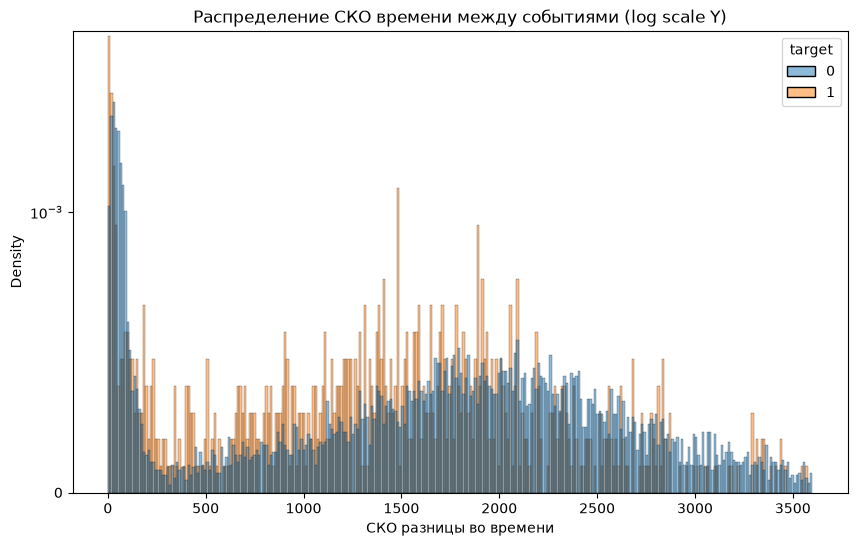

In [44]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=diffs_stats,
    x='time_diff_std',
    hue='target',
    bins=300,
    binrange=(0, 3600),
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('symlog', linthresh=0.001)
plt.title('Распределение СКО времени между событиями (log scale Y)')
plt.xlabel('СКО разницы во времени')
plt.show()


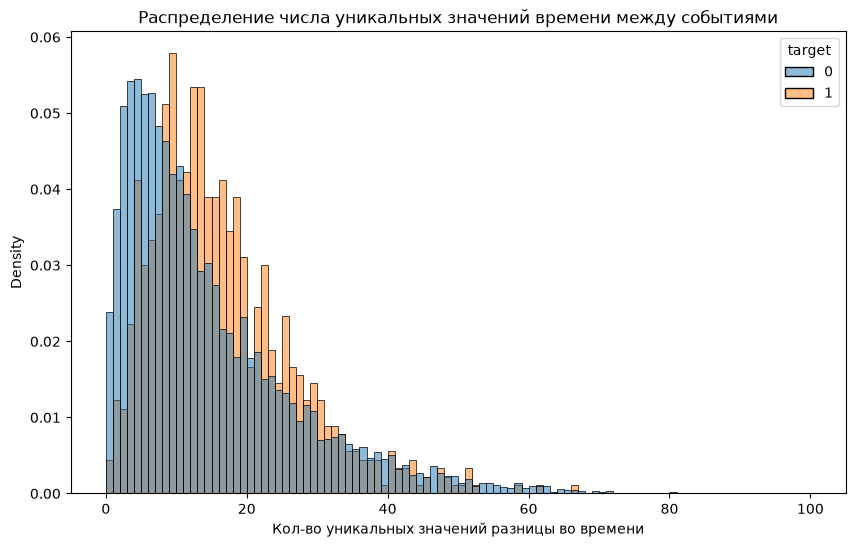

In [45]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=diffs_stats,
    x='time_diff_nunique',
    hue='target',
    bins=100,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.title('Распределение числа уникальных значений времени между событиями')
plt.xlabel('Кол-во уникальных значений разницы во времени')
plt.show()


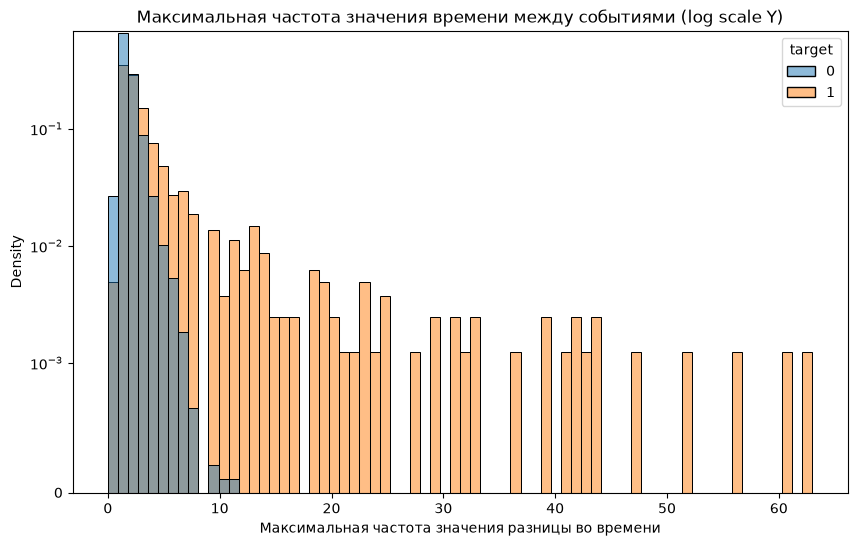

In [46]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=diffs_stats,
    x='time_diff_max_freq',
    hue='target',
    bins=70,
    alpha=0.5,
    common_norm=False,
    stat='density',
)

plt.yscale('symlog', linthresh=0.001)
plt.title('Максимальная частота значения времени между событиями (log scale Y)')
plt.xlabel('Максимальная частота значения разницы во времени')
plt.show()


**Выводы по динамике времени между событиями (`time_diff`, по результатам анализа гистограмм):**
* **Повторяемость интервалов (`time_diff_max_freq`) - самый мощный временной признак:**
  * Реальные пользователи (`target = 0`) преобладают только при `time_diff_max_freq <= 2` (одинаковая с точностью до секунды пауза между событиями встречается не более 1–2 раз за сессию).
  * Начиная с **`time_diff_max_freq >= 3`** плотность ботов выше на порядок, а при **`time_diff_max_freq >= 12` (и вплоть до `63` повторений одного и того же интервала)** реальные пользователи полностью исчезают - остаются **исключительно боты** с фиксированным таймером (`sleep`).
* **Минимальная, медианная и средняя паузы (`time_diff_min`, `time_diff_median`, `time_diff_mean`):**
  * На всех трёх графиках у ботов выделяются **два характерных режима работы**:
    1. **Быстрый парсинг:** пик плотности в самых первых бинах у нуля (`0–8` с для `time_diff_min`, `0–30` с для медианы и среднего), где скрипты генерируют запросы практически без задержки.
    2. **Периодический обход по расписанию:** повышенная плотность ботов на средних интервалах (`90–600` с для `time_diff_min`, `250–1100` с для `time_diff_median` и `150–500` с для `time_diff_mean`), тогда как обычным пользователям свойственны естественные паузы в `10–90` с (просмотр карточек подряд) либо длинные перерывы между сессиями (`> 1200` с).
* **Разброс и число уникальных пауз (`time_diff_std`, `time_diff_nunique`):**
  * В `time_diff_std` боты дают выраженный пик около `0` (`0–20` с - постоянная задержка с околонулевой дисперсией) и превышают плотность людей в диапазоне `150–2200` с.
  * В `time_diff_nunique` люди преобладают при `0–8` уникальных значениях пауз (в силу меньшего общего числа событий в сессии), а боты - в диапазоне `9–33` уникальных интервалов.
* Для сессий из одного события (`count == 1`), где интервал между событиями не определён, признаки корректно заполняются константами (`-1` и `0`).

## Обучающая и тестовая выборки

### Для бейзлайна:

In [47]:
def basic_features(ev, meta):
    g = ev.groupby('cookie_id')
    f = pd.DataFrame(
        {
            'n_events': g.size(),
            'item_nunique': g.item_id.nunique(),
        }
    )
    f = meta[['cookie_id']].merge(f.reset_index(), on='cookie_id', how='left')
    return f.fillna(0)


Xtr_baseline = basic_features(ev_tr.drop('target', axis=1), train)
Xte_baseline = basic_features(ev_te, test)
ytr = train.target.values

Xtr_baseline.head()


,cookie_id,n_events,item_nunique
0,ck_54a059eb7d3ea68b,7,4
1,ck_7e4de46eeab82974,41,19
2,ck_9320229ef6304522,36,19
3,ck_30ccd25bc1714ed9,21,10
4,ck_a77c5f05948cdeef,29,16


### Для модели:

In [48]:
def complex_features(ev, meta):
    f = (
        ev.sort_values(['cookie_id', 'event_ts', 'eid', 'event_name'], kind='mergesort')
        .groupby('cookie_id')
        .agg(
            common_event=('event_name', lambda x: x.mode().iat[0]),
            common_platform=('platform', lambda x: x.mode().iat[0]),
            common_user_agent=('user_agent', lambda x: x.mode().iat[0]),
            script_ua=(
                'user_agent',
                lambda x: np.isin(desktop_script_user_agents, x).any(),
            ),
            nunique_items=('item_id', 'nunique'),
            item_events=('item_id', lambda x: (~x.isna()).sum()),
            item_view_times=('event_name', lambda x: (x == 'item_view').sum()),
            search_times=('event_name', lambda x: (x == 'search_results_view').sum()),
            photo_swipe_times=('event_name', lambda x: (x == 'photo_swipe').sum()),
            favorite_add_times=('event_name', lambda x: (x == 'favorite_add').sum()),
            seller_view_times=('event_name', lambda x: (x == 'seller_page_view').sum()),
            login_times=('event_name', lambda x: (x == 'login').sum()),
            contact_show_times=(
                'event_name',
                lambda x: (x == 'contact_phone_show').sum(),
            ),
            chat_open_times=('event_name', lambda x: (x == 'contact_chat_open').sum()),
            message_sent_times=(
                'event_name',
                lambda x: (x == 'contact_message_sent').sum(),
            ),
            nunique_cats=('item_category', 'nunique'),
            loc_max_freq=(
                'item_location',
                lambda x: (
                    Counter(x[~x.isna()]).most_common(1)[0][1] / ((~x.isna()).sum() + 1)
                    if (~x.isna()).any()
                    else 0
                ),
            ),
            seller_type_pro=('seller_type', lambda x: (x == 'pro').any()),
            seller_type_private=('seller_type', lambda x: (x == 'private').any()),
            seller_type_default=('seller_type', lambda x: (x == 'default').any()),
            seller_page_view_first=(
                'event_name',
                lambda x: x.iloc[0] == 'seller_page_view',
            ),
            search_page_max=('search_page', 'max'),
            search_page_first=(
                'search_page',
                lambda x: x[~x.isna()].iloc[0].item() if (~x.isna()).any() else 0,
            ),  # groupby preserves the order of rows within each group
            nunique_search_query=('search_query', 'nunique'),
            pointer_x_max_freq=(
                'pointer_x',
                lambda x: (
                    Counter(x[~x.isna()]).most_common(1)[0][1]
                    if (~x.isna()).any()
                    else 0
                ),
            ),
            pointer_y_max_freq=(
                'pointer_y',
                lambda x: (
                    Counter(x[~x.isna()]).most_common(1)[0][1]
                    if (~x.isna()).any()
                    else 0
                ),
            ),
        )
        .reset_index()
    )

    f.loc[f['search_page_max'].isna(), 'search_page_max'] = 0

    f['item_events_per_unique_item'] = f['item_events'] / (f['nunique_items'] + 1)
    f['contact_show_times_per_unique_item'] = f['contact_show_times'] / (
        f['nunique_items'] + 1
    )
    f['photo_swipe_per_unique_item'] = f['photo_swipe_times'] / (f['nunique_items'] + 1)
    # f['changes_client_metadata'] = f['switches_platform'] | f['switches_agent']

    f['search_per_item_view'] = f['search_times'] / (f['item_view_times'] + 1)
    f['seller_view_per_item_view'] = f['seller_view_times'] / (f['item_view_times'] + 1)

    f['message_sent_per_chat_open'] = f['message_sent_times'] / (
        f['chat_open_times'] + 1
    )

    f['forbidden_ua_substrings'] = f['common_platform'].map(
        platform_ua_conflict_markers
    )
    f['client_metadata_conflict'] = [
        any(sub in text for sub in forbidden)
        for text, forbidden in zip(
            f['common_user_agent'],
            f['forbidden_ua_substrings'],
        )
    ]

    f = f.drop(
        [
            'common_platform',
            'common_user_agent',
            'item_events',
            'item_view_times',
            'search_times',
            'photo_swipe_times',
            'contact_show_times',
            'message_sent_times',
            'forbidden_ua_substrings',
        ],
        axis=1,
    )

    ev_plus_diff = ev.copy()

    ev_plus_diff['time_diff'] = (
        ev_plus_diff.sort_values('event_ts')
        .groupby('cookie_id')['event_ts']
        .diff()
        .dt.total_seconds()
    )
    diffs_stats = (
        ev_plus_diff.groupby('cookie_id')
        .agg(
            count=('event_ts', 'count'),
            time_diff_min=('time_diff', 'min'),
            time_diff_mean=('time_diff', 'mean'),
            time_diff_median=('time_diff', 'median'),
            time_diff_std=('time_diff', 'std'),
            time_diff_nunique=('time_diff', 'nunique'),
            time_diff_max_freq=('time_diff', lambda x: Counter(x).most_common(1)[0][1]),
        )
        .reset_index()
    )
    diffs_stats.loc[
        diffs_stats['count'] == 1, ['time_diff_nunique', 'time_diff_max_freq']
    ] = 0
    diffs_stats.loc[
        diffs_stats['count'] == 1,
        ['time_diff_min', 'time_diff_mean', 'time_diff_median', 'time_diff_std'],
    ] = -1
    diffs_stats.loc[diffs_stats['time_diff_std'].isna(), 'time_diff_std'] = -1

    f = meta[['cookie_id']].merge(f.reset_index(drop=True), on='cookie_id', how='left')
    f = f.merge(diffs_stats.reset_index(drop=True), on='cookie_id', how='left')
    return f


Xtr = complex_features(ev_tr.drop('target', axis=1), train)
Xte = complex_features(ev_te, test)

Xtr.head()


,cookie_id,common_event,script_ua,nunique_items,favorite_add_times,seller_view_times,login_times,chat_open_times,nunique_cats,loc_max_freq,...,seller_view_per_item_view,message_sent_per_chat_open,client_metadata_conflict,count,time_diff_min,time_diff_mean,time_diff_median,time_diff_std,time_diff_nunique,time_diff_max_freq
0,ck_54a059eb7d3ea68b,item_view,False,4,0,0,0,0,3,0.375000,...,0.000000,0.0,False,7,1.0,27.833333,21.0,29.949402,6,1
1,ck_7e4de46eeab82974,item_view,False,19,1,4,1,0,1,0.315789,...,0.173913,0.0,False,41,2.0,986.900000,57.5,2416.286861,36,2
2,ck_9320229ef6304522,search_results_view,False,19,3,3,3,1,7,0.647059,...,0.375000,0.5,False,36,1.0,1042.600000,22.0,2306.449400,27,3
3,ck_30ccd25bc1714ed9,item_view,False,10,0,2,0,1,1,0.476190,...,0.133333,0.0,False,21,6.0,861.050000,54.5,2502.081501,18,2
4,ck_a77c5f05948cdeef,item_view,False,16,2,3,0,0,4,0.724138,...,0.214286,0.0,False,29,0.0,682.071429,51.5,1720.954514,27,2


**Итог формирования признакового пространства:**
Для основной модели сконструирован набор из **31 информативного признака** на уровне сессии (`cookie_id`), объединяющий:
* **клиентские маркеры:** индикатор скриптового User-Agent (`script_ua`), маркер конфликта платформы и User-Agent (`client_metadata_conflict`) и наиболее частый тип события (`common_event`);
* **счётчики и пропорции действий:** число уникальных товаров, категорий и поисковых запросов, интенсивность просмотров, свайпов фото, открытий телефонов, чатов и отправленных сообщений в пересчёте на карточку или просмотр;
* **паттерны пагинации и кликов:** первая и максимальная страница поиска (`search_page_first`, `search_page_max`), концентрация локаций (`loc_max_freq`) и максимальная частота совпадения координат курсора (`pointer_x_max_freq`, `pointer_y_max_freq`);
* **тайминги сессии:** общее число событий (`count`) и статистики интервалов между событиями (`time_diff_min`, `time_diff_mean`, `time_diff_median`, `time_diff_std`, `time_diff_nunique`, `time_diff_max_freq`).

# Валидация и подбор гиперпараметров

Тест лежит **позже** трейна по времени, поэтому и валидацию честно делать по времени, а не
случайным сплитом.

Метрику берём из `metric.py` - это ровно тот код, которым считает проверяющая система.
Своя реализация почти наверняка разойдётся с официальной на одинаковых `score`:
их нельзя разделять, группа равных значений отмечается целиком.

In [49]:
ev_tr.event_ts.max() < ev_te.event_ts.min()


True

## Валидация бейзлайна

In [50]:
from sklearn.ensemble import RandomForestClassifier

from metric import (
    precision_at_recall,
)  # официальная реализация, ей же считает автопроверка

is_valid = train.window_start_ts.ge('2026-04-17').values
cols = ['n_events', 'item_nunique']

model = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED)
model.fit(Xtr_baseline.loc[~is_valid, cols], ytr[~is_valid])
p_va = model.predict_proba(Xtr_baseline.loc[is_valid, cols])[:, 1]

print('P@R0.7 на валидации:', round(precision_at_recall(ytr[is_valid], p_va), 4))
print('доля ботов (это уровень константы):', round(ytr[is_valid].mean(), 4))


P@R0.7 на валидации: 0.1062
доля ботов (это уровень константы): 0.082


In [51]:
(~is_valid).sum().item(), is_valid.sum().item()


(9140, 1951)

**Выводы по валидации бейзлайна:**
* Проверка `ev_tr.event_ts.max() < ev_te.event_ts.min()` подтверждает, что тестовая выборка целиком лежит в будущем относительно обучающей. В качестве валидационной выборки выделены сессии с `window_start_ts >= 2026-04-17` (**1 951** кука в валидации против **9 140** в обучении, что составляет ~17.6% данных).
* Базовая модель `RandomForestClassifier` на двух простых счётчиках (`n_events`, `item_nunique`) достигает на валидации лишь **`P@R0.7 = 0.1062`**, что совсем незначительно превышает константное предсказание (уровень доли ботов в валидации - **`0.0820`**). Это доказывает, что одних только объёмных показателей активности недостаточно для качественного выделения ботов при высокой полноте.

## Валидация модели

### Настройка гипепараметров:

In [52]:
import optuna
from catboost import CatBoostClassifier

cols = Xtr.columns.copy()
cols = cols[
    ~cols.isin(['cookie_id', 'client_metadata_conflict', 'time_diff_mean', 'target'])
]
cat_features = ['common_event']

main_params = {
    'cat_features': cat_features,
    'iterations': 2000,
    'eval_metric': 'Logloss',
    'early_stopping_rounds': 100,
    'verbose': False,
    'random_seed': SEED,
}


def objective(trial, X_train, y_train, X_val, y_val):
    params = {
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 15),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 10, log=True),
        'auto_class_weights': trial.suggest_categorical(
            'auto_class_weights', ['None', 'Balanced', 'SqrtBalanced']
        ),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
    }

    params.update(main_params)

    model = CatBoostClassifier(**params)
    model.fit(X_train, y_train, eval_set=(X_val, y_val))

    preds = model.predict_proba(X_val)[:, 1]

    p_at_r70 = precision_at_recall(y_val, preds)

    return p_at_r70


sampler = optuna.samplers.TPESampler(seed=SEED)
study = optuna.create_study(direction='maximize', sampler=sampler)
study.optimize(
    lambda trial: objective(
        trial,
        Xtr.loc[~is_valid, cols],
        ytr[~is_valid],
        Xtr.loc[is_valid, cols],
        ytr[is_valid],
    ),
    n_trials=50,
)


c:\Users\PC\OneDrive\!Contests\Avito_Bootcamp-Autumn_2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-10-12 21:38:46,517] A new study created in memory with name: no-name-e8fd7c9f-2490-4e66-a041-29872f9af943
[I 2026-10-12 21:39:40,337] Trial 0 finished with value: 0.5517241379310345 and parameters: {'learning_rate': 0.023688639503640783, 'depth': 8, 'l2_leaf_reg': 11.247915185359671, 'random_strength': 0.24810409748678125, 'auto_class_weights': 'None', 'bagging_temperature': 0.8661761457749352}. Best is trial 0 with value: 0.5517241379310345.
[I 2026-10-12 21:40:03,450] Trial 1 finished with value: 0.5989304812834224 and parameters: {'learning_rate': 0.039913058785616795, 'depth': 7, 'l2_leaf_reg': 1.2881829201412343, 'random_strength': 7.579479953348009, 'auto_class_weights': 'None', 'bagging_te

### Лучшая модель:

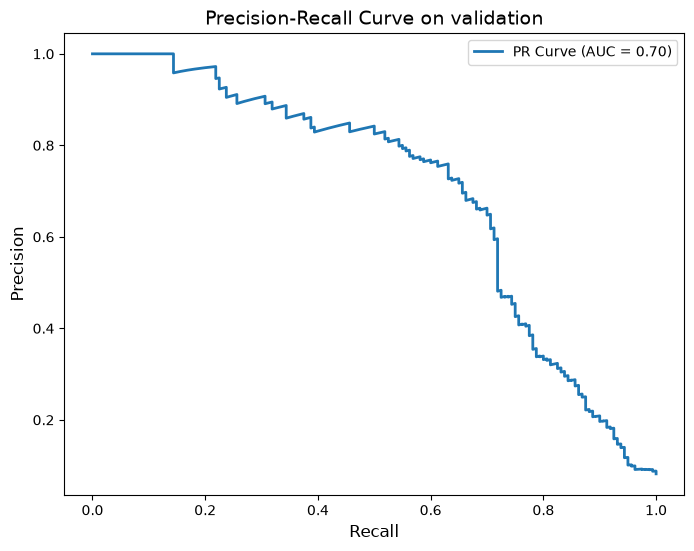

In [53]:
from sklearn.metrics import auc, precision_recall_curve

params = main_params.copy()
params.update(study.best_params)

model = CatBoostClassifier(**params)
model.fit(
    Xtr.loc[~is_valid, cols],
    ytr[~is_valid],
    eval_set=(Xtr.loc[is_valid, cols], ytr[is_valid]),
)

preds = model.predict_proba(Xtr.loc[is_valid, cols])[:, 1]

precision, recall, _ = precision_recall_curve(ytr[is_valid], preds)

pr_auc = auc(recall, precision)

# Строим график
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'PR Curve (AUC = {pr_auc:.2f})', linewidth=2)
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve on validation', fontsize=14)
plt.legend()
plt.show()


**Выводы по настройке и валидации основной модели (`CatBoostClassifier` + `Optuna`):**
* Оптимизация гиперпараметров `CatBoostClassifier` (50 итераций `TPESampler` с ранней остановкой по валидации) на обновлённом наборе признаков позволила поднять целевую метрику `Precision @ Recall >= 0.70` на валидации с **`0.1062`** (бейзлайн) до **`0.6627`** (Trial 14, рост более чем в **6.2 раза**), а площадь под PR-кривой выросла до **`PR-AUC = 0.70`**.
* **Интерпретация графика PR-кривой на валидации:**
  1. В условиях сильного дисбаланса классов (базовый уровень `Precision = 0.082`) полученная площадь под PR-кривой (`0.70`) свидетельствует о высокой разделяющей способности модели.
  2. В левой части графика (вплоть до `Recall ≈ 0.50`) модель удерживает очень высокую точность (`Precision > 0.83–0.85`), безошибочно отлавливая явных ботов (скриптовые User-Agent, агрессивный парсинг, сверхкороткие тайминги).
  3. По мере приближения к целевому порогу `Recall = 0.70` точность плавно снижается до **`~0.66`**, так как для достижения 70% полноты модели приходится захватывать более сложные («мимикрирующие» под людей или низкоактивные) сессии, а также сказывается небольшой временной сдвиг (temporal drift) в распределении новых ботов в конце апреля.

# Сабмит

In [54]:
model.fit(Xtr[cols], ytr)

p_va = model.predict_proba(Xtr[cols])[:, 1]
print('P@R0.7 на всей обучающей выборке:', round(precision_at_recall(ytr, p_va), 4))


P@R0.7 на всей обучающей выборке: 1.0


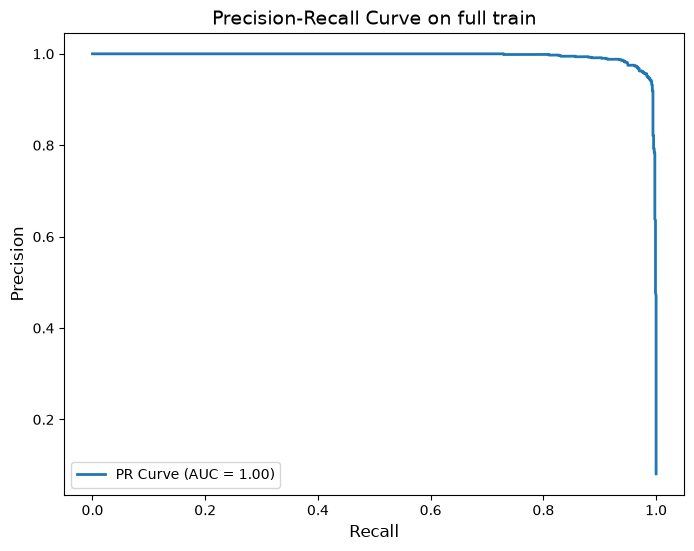

In [55]:
precision, recall, _ = precision_recall_curve(ytr, p_va)

pr_auc = auc(recall, precision)

# Строим график
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'PR Curve (AUC = {pr_auc:.2f})', linewidth=2)
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve on full train', fontsize=14)
plt.legend()
plt.show()


In [56]:
sub = pd.DataFrame(
    {
        'cookie_id': Xte.cookie_id,
        'score': model.predict_proba(Xte[cols])[:, 1],
    }
)
assert len(sub) == len(test) and sub.score.between(0, 1).all()
sub.to_csv('submission.csv', index=False)
sub.head()


,cookie_id,score
0,ck_315fb710a0e371e7,0.000704
1,ck_a76ee3b3e3e522fd,0.055152
2,ck_94c9a4d382689e82,0.048261
3,ck_8eaf9509ad9462a0,0.001518
4,ck_9a88a5a989cb5bc6,0.010213


## Итоговые выводы

**Качество финальной модели:** выделение категории продавца `default` для событий с непустым `item_id` устранило смешивание структурных пропусков (поиск/логин) с типом продавца. Вместе с учетом технических сигнатур (`script_ua`), поведенческих пропорций (глубина и старт пагинации поиска, конверсия просмотров в открытие контактов, статика координат кликов) и временны́х интервалов между событиями (`time_diff`) это позволило поднять метрику на валидации до **`0.6627`** (`PR-AUC = 0.70`). После дообучения `CatBoostClassifier` с лучшими найденными гиперпараметрами на полном объёме обучающей выборки (`Xtr`) метрика на трейне составила **`P@R0.7 = 1.0`** (`PR-AUC = 1.00`).